# Данные

Данные были получены с Высокогорного института в Нальчике.
Содержание таблицы это данные метеорологического радара и регистраторов грозы, собранные на Северном Кавказе (КБР, КЧР, Ставропольской Край, край ЧР и Ингушетии).

В каждой строчке приведены такие данные:
- Khail – категория градоопасности облака, от 1 категории (самое слабая) до 4 (самое мощное);
- Zmax — максимальная радиолокационная отражаемость облака (dBz);
- HZm —высота максимума радиоэха облака над уровнем нулевой изотермы H0 (км);
- dH35 и dH45 – превышение над уровнем Н0 высот верхней границы объемов радиоэха с Zm, равным 35 и 45 dBZ, соответственно (км);
- dVIL— максимальное значение вертикально проинтегрированной водности облака выше уровня Н0 (кг/м2);
- dVIL/dt прирост (производная по времени) приведенной водности КЯ выше уровня Н0 (кг/м2) за межобзорный интервал dt;


Грозопеленгационные характеристики (за каждый 3,5‑минутный интервал):
- VHF количество грозовых разрядов типа «облако–облако» в минуту;
- (LF-, LF+) количество грозовых разрядов типа «облако–земля» отрицательной и положительной полярности соответственно.

Y – переменная «гроза», определена простой бинарной классификацией:
- Y=1, если за данный 3,5‑минутный интервал зарегистрирован хотя бы один разряд любого типа (VHF, LF-, LF+).
- Y=0 – не зарегистрировано ни одного разряда.

In [8]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / 'raw'

file_name = DATA_DIR / 'RUST_Parameters.xlsx'

In [9]:
import pandas as pd


df = pd.read_excel(file_name)
df.head()

,Khail,Zmax,HZmax,dH35,dH45,dVIL,dVIL/dt,VHF total (count min-1),LF- (count min-1),LF+ (count min-1),Lftotal,Ntotal,Y
0,1,32,5.0,0.0,0.0,0.6,0.171429,0,0.0,0.0,0.0,0.0,0
1,2,47,5.0,4.1,1.8,4.4,1.257143,0,0.0,0.0,0.0,0.0,0
2,2,54,6.2,6.0,4.1,10.5,3.000000,3,3.2,1.1,4.3,7.3,1
3,3,60,3.5,6.9,5.6,19.1,5.457143,8,11.6,1.9,13.5,21.5,1
4,3,63,3.5,8.2,6.0,19.6,5.600000,34,18.7,0.8,19.5,53.5,1


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 994 entries, 0 to 993
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Khail                    994 non-null    int64  
 1   Zmax                     994 non-null    int64  
 2   HZmax                    994 non-null    float64
 3   dH35                     994 non-null    float64
 4   dH45                     994 non-null    float64
 5   dVIL                     994 non-null    float64
 6   dVIL/dt                  994 non-null    float64
 7   VHF total (count min-1)  994 non-null    int64  
 8   LF- (count min-1)        994 non-null    float64
 9   LF+ (count min-1)        994 non-null    float64
 10  Lftotal                  994 non-null    float64
 11  Ntotal                   994 non-null    float64
 12  Y                        994 non-null    int64  
dtypes: float64(9), int64(4)
memory usage: 101.1 KB


Видим что пропущенных значении нет, поэтому можем сразу сделать EDA

In [11]:
df.describe()

,Khail,Zmax,HZmax,dH35,dH45,dVIL,dVIL/dt,VHF total (count min-1),LF- (count min-1),LF+ (count min-1),Lftotal,Ntotal,Y
count,994.000000,994.000000,994.000000,994.000000,994.000000,994.000000,994.000000,994.000000,994.000000,994.000000,994.000000,994.000000,994.000000
mean,2.540241,57.546278,4.457847,5.042857,3.345473,16.977867,4.850819,23.493964,5.042656,1.719718,6.762374,30.256338,0.839034
std,0.884515,8.682051,5.969167,2.213361,2.272934,18.338984,5.239710,54.755085,7.826585,3.714851,10.511600,59.929010,0.367684
min,1.000000,24.000000,0.500000,0.000000,0.000000,0.100000,0.028571,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,52.000000,2.200000,3.700000,1.500000,4.500000,1.285714,1.000000,0.300000,0.000000,0.500000,2.000000,1.000000
50%,3.000000,59.000000,3.500000,5.400000,3.600000,11.150000,3.185714,4.000000,1.900000,0.300000,2.600000,9.500000,1.000000
75%,3.000000,64.000000,4.800000,6.375000,4.900000,23.450000,6.700000,20.000000,6.400000,1.600000,8.300000,31.400000,1.000000
max,4.000000,76.000000,54.000000,13.900000,9.300000,166.200000,47.485714,466.000000,58.100000,37.000000,79.200000,479.000000,1.000000


# Сделаем двухстадийную модель. Первая будет предсказывать грозу, а вторая интенсивность молний в этой грозе 
## Таргет 1 - Y (0 или 1) наличие или отсутствие грозы
## Таргет 2 - S = VHF + (LF-) + (LF+) в таблице представлен как Ntotal

Проведем анализ Y. Посмотрим на баланс классов и сразу выберем метрики

Text(0.5, 1.0, 'Распределение таргета')

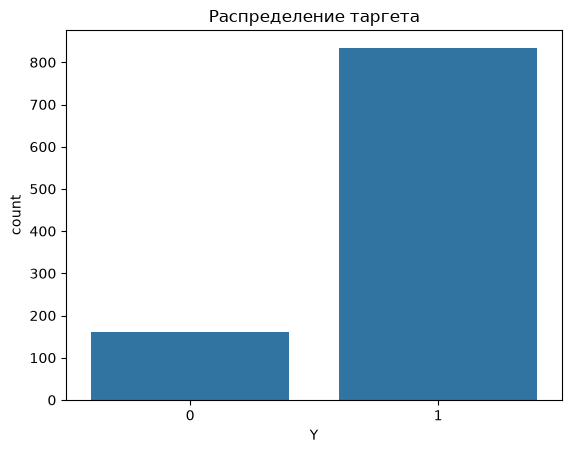

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=df, x = 'Y')
plt.title("Распределение таргета")

Видим сильный дисбаланс классов в сторону положительного. Сразу определим какие метрики смотреть.

Нам на самом деле важнее не пропустить молниевую активность, поэтому лучше смотреть на Recall т.е. долю грозовых активностей которую мы обнаружили.

Дальше смотрим на Precision, т.к. мы не хотим чтобы наша модель вносила в грозы много негрозовых облаков, чтобы не так часто были предупреждения.

Дальше можно посмотреть PR-AUC и ROC-AUC.

# Хорошо, теперь посмотрим на распределения признаков из радаров, не грозопеленгационных


Начнем с Khail. Он показывает градоопасность облако, хотя сама по себе градоопасность не имеет явную зависимость с грозой, она может давать большую конвекцию, тем самых увеличивая электризацию облака

Построим график распределения Khail

Text(0.5, 1.0, 'Распределение градоопасности облака')

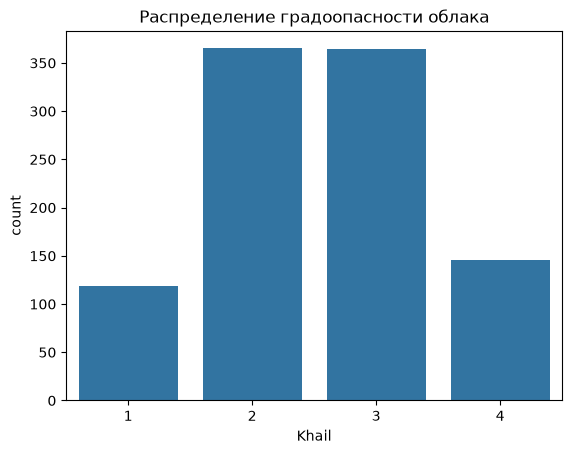

In [14]:
sns.countplot(data=df, x='Khail')
plt.title("Распределение градоопасности облака")

Мы видим что в представленых данных облак со средней градоопасностью больше чем с высокой и низкой. Можно предположить что чем градоопаснее облако, тем выше вероятность грозы

In [17]:
group_khail = df.groupby("Khail")['Y'].mean()
group_khail

Khail
1    0.142857
2    0.841096
3    1.000000
4    1.000000
Name: Y, dtype: float64

Text(0.5, 1.0, 'Эмпирическая вероятность грозы в зависимости от градоопасности облака')

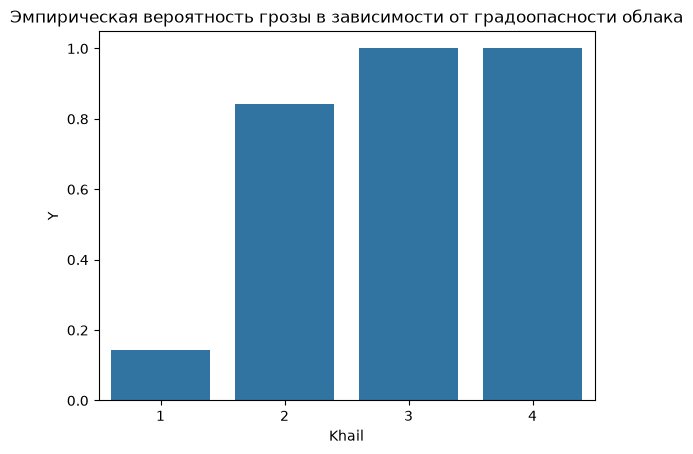

In [19]:
sns.barplot(data=group_khail)
plt.title("Эмпирическая вероятность грозы в зависимости от градоопасности облака")

Как видим на графике, чем выше градоопасность облака, тем вероятнее гроза, в предоставленных данных. В 3 и 4 степени градоопасноти даже нет облак без грозы.

Однако еще не факт, что Khail сильно влияет на предсказание. Проверим это потом как ML-эксперимент обучив несколько моделей на выборке с признаком и без признака. И посмотрим метрики